# Real rate profiles, the WT window estimator and sketched estimation (Experiment 7)

Run **after** `4_Final_Tables.ipynb` (it reads `results/final/exp6_all_estimates.csv`). Nothing existing is changed;
outputs go to `results/final/` (new file names) and `results/exp7/`. **Runtime: about 50 minutes** on a Colab CPU runtime.

| Part | What | Time |
|---|---|---|
| A | **Real mutation-rate profiles** from the alignments of the 100 real pairs: how uneven, how regional, what shape; does the k-mer α track it? | 1 min |
| B | Starts **Experiment 7** in the background: 360 pairs simulated from real chromosomes with **real** rate profiles (24 real pairs × 3 chromosomes × 5 ANI levels) | runs ~45 min |
| C | **New window-based estimator (WT)** on all 1,260 Experiment 6 pairs. Designed on replicate 0; **tested on replicates 1–9** | 3 min |
| D | WT on the 100 real genome pairs + Figure 4 (k-mer α vs alignment α) | 1 min |
| E | Experiment 7 results + our estimator on **FracMinHash sketches** (1 in 100 and 1 in 1000 k-mers: the fast version) | 2 min |
| F | `key_numbers_v2.txt` | seconds |

Keep the tab open. If Colab disconnects: Run all again (finished Experiment 7 pairs are skipped).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
PROJECT = "/content/drive/MyDrive/CMPS355_ANI_Project"
TOOLS   = "/content/tools"
LIB     = "/content/final_lib"
QUICK7  = False          # True = 12-pair test of Experiment 7 (separate _quick files)

import os, sys, glob, time
RESULTS = f"{PROJECT}/results"; RS = f"{RESULTS}/realsim"; OUTF = f"{RESULTS}/final"; OUT7 = f"{RESULTS}/exp7"
TAG7 = "_quick" if QUICK7 else ""
for d in [OUTF, OUT7, TOOLS, LIB]: os.makedirs(d, exist_ok=True)
open(f"{LIB}/__init__.py", "w").close(); sys.path.insert(0, os.path.dirname(LIB))
assert os.path.exists(f"{OUTF}/exp6_all_estimates.csv"), "run 4_Final_Tables.ipynb first"
assert len(glob.glob(f"{RS}/curves/job_*.npz")) > 0 and os.path.exists(f"{RESULTS}/multitool/real_all_tools.csv")
print("Experiment 6 count files:", len(glob.glob(f"{RS}/curves/job_*.npz")), "| writing to", OUTF, "and", OUT7)

Experiment 6 count files: 1260 | writing to /content/drive/MyDrive/CMPS355_ANI_Project/results/final and /content/drive/MyDrive/CMPS355_ANI_Project/results/exp7


In [3]:
# ---------------- tools for Experiment 7: pyskani, sourmash, Mash 2.3 ----------------
import subprocess
subprocess.run("pip -q install pyskani sourmash", shell=True, check=True)
if not os.path.exists(f"{TOOLS}/mash-Linux64-v2.3/mash"):
    subprocess.run(f"cd {TOOLS} && wget -q https://github.com/marbl/Mash/releases/download/v2.3/mash-Linux64-v2.3.tar "
                   "&& tar -xf mash-Linux64-v2.3.tar", shell=True, check=True)
import pyskani, sourmash
print("pyskani", pyskani.__version__, "| sourmash", sourmash.VERSION, "| Mash", subprocess.run([f"{TOOLS}/mash-Linux64-v2.3/mash", "--version"],
      capture_output=True, text=True).stdout.strip(), "| CPUs", os.cpu_count())

pyskani 0.3.0 | sourmash 4.9.4 | Mash 2.3 | CPUs 2


### Shared code

In [4]:
%%writefile {LIB}/estimators.py
# ---------------- estimators shared by all parts (gamma copied unchanged from the project) ----------------
import numpy as np
from scipy.optimize import curve_fit, least_squares

KS = np.arange(15, 32, 2)

def gamma_model(k, s, d, alpha): return np.log(s) - alpha * np.log1p(k * d / alpha)

def est_gamma(C, ks=KS):
    """original multi-k gamma (s free) -> ANI, s, alpha"""
    y = np.log(C); slope, inter = np.polyfit(ks, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), d0, a0], bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(ks, *p) - y) ** 2)
            if best is None or err < best[1]: best = (p, err)
        except RuntimeError: pass
    s, d, a = best[0]; return (1 + d / a) ** (-a), s, a

def est_gamma_s_fixed(C, s_fixed, ks=KS):
    """C: window s, then gamma fit of d and alpha -> ANI"""
    y = np.log(np.maximum(C, 1e-12)); slope, _ = np.polyfit(ks, y, 1); d0 = max(-slope, 1e-4); best = None
    f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
    for a0 in [0.3, 1, 5, 50]:
        try:
            q, _ = curve_fit(f, ks, y, p0=[d0, a0], bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000)
            sse = np.sum((f(ks, *q) - y) ** 2)
            if best is None or sse < best[1]: best = (q, sse)
        except (RuntimeError, ValueError): pass
    d, a = best[0]; return (1 + d / a) ** (-a)

# ---------------- two-rate-class model (proposal, Table 1) ----------------
# Shared regions come in two classes: a fraction f with identity q1 and 1-f with identity q2 <= q1.
#   C(k) = s * [ f q1^k + (1-f) q2^k ],   ANI = f q1 + (1-f) q2
# Settings fixed in advance (not tuned on results): identities limited to [0.60, 1] (below ~60% identity
# a region is no longer recognisably homologous), multi-start least squares on log C(k), k = 15..31.
Q_MIN = 0.60

def _two_class_log(k, s, f, q1, q2):
    return np.log(s) + np.log(f * q1 ** k + (1 - f) * q2 ** k + 1e-300)

def est_two_class(C, s_fixed=None, ks=KS):
    """-> ANI, s, f, q1, q2.  s free, or fixed (e.g. to the window estimate)"""
    ks = np.asarray(ks, float); y = np.log(np.maximum(C, 1e-12)); best = None
    slope, inter = np.polyfit(ks, y, 1); q0 = float(np.clip(np.exp(slope), Q_MIN + 0.01, 0.999))
    for f0 in (0.3, 0.6, 0.9):
        for gap in (0.02, 0.08, 0.2):
            q1_0 = min(0.999, q0 + gap / 2); q2_0 = max(Q_MIN + 0.005, q0 - gap / 2)
            if s_fixed is None:
                x0 = [min(np.exp(inter), 0.99) if inter < 0 else 0.9, f0, q1_0, q2_0]
                lo, hi = [1e-6, 0, Q_MIN, Q_MIN], [1, 1, 1, 1]
                fun = lambda p: _two_class_log(ks, p[0], p[1], p[2], min(p[3], p[2])) - y
            else:
                x0 = [f0, q1_0, q2_0]; lo, hi = [0, Q_MIN, Q_MIN], [1, 1, 1]
                fun = lambda p: _two_class_log(ks, s_fixed, p[0], p[1], min(p[2], p[1])) - y
            try:
                r = least_squares(fun, x0, bounds=(lo, hi), max_nfev=5000)
                if best is None or r.cost < best.cost: best = r
            except ValueError: pass
    p = best.x
    s, f, q1, q2 = (p[0], p[1], p[2], min(p[3], p[2])) if s_fixed is None else (s_fixed, p[0], p[1], min(p[2], p[1]))
    return f * q1 + (1 - f) * q2, s, f, q1, q2

# ---------------- choosing between the two models per pair (AICc; rule fixed in advance) ----------------
def _sse_gamma(C, s, d, a, ks=KS): return float(np.sum((gamma_model(np.asarray(ks, float), s, d, a) - np.log(C)) ** 2))

def gamma_fit(C, s_fixed=None, ks=KS):
    """-> ANI, s, d, alpha, SSE   (identical results to est_gamma / est_gamma_s_fixed)"""
    y = np.log(np.maximum(C, 1e-12)); slope, inter = np.polyfit(ks, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            if s_fixed is None:
                p, _ = curve_fit(gamma_model, ks, y, p0=[min(s0, 0.99), d0, a0], bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            else:
                f = lambda k, d, a: gamma_model(k, s_fixed, d, a)
                q, _ = curve_fit(f, ks, y, p0=[d0, a0], bounds=([1e-6, 0.01], [3, 1000]), maxfev=20000); p = np.array([s_fixed, *q])
            sse = np.sum((gamma_model(ks, *p) - y) ** 2)
            if best is None or sse < best[1]: best = (p, sse)
        except (RuntimeError, ValueError): pass
    s, d, a = best[0]; return (1 + d / a) ** (-a), s, d, a, float(best[1])

def two_class_fit(C, s_fixed=None, ks=KS):
    ani, s, f, q1, q2 = est_two_class(C, s_fixed, ks)
    sse = float(np.sum((_two_class_log(np.asarray(ks, float), s, f, q1, q2) - np.log(np.maximum(C, 1e-12))) ** 2))
    return ani, s, f, q1, q2, sse

def aicc(sse, n, p): return n * np.log(max(sse, 1e-300) / n) + 2 * p + 2 * p * (p + 1) / (n - p - 1)

def select_model(C, s_fixed=None, ks=KS):
    """fit both models; return the ANI of the one with the lower AICc (+ both ANIs and the choice)"""
    g = gamma_fit(C, s_fixed, ks); t = two_class_fit(C, s_fixed, ks); n = len(ks)
    pg, pt = (3, 4) if s_fixed is None else (2, 3)
    use_two = aicc(t[-1], n, pt) < aicc(g[-1], n, pg)
    return (t[0] if use_two else g[0]), g[0], t[0], bool(use_two)


Writing /content/final_lib/estimators.py


In [5]:
%%writefile {LIB}/window_est.py
# ---------------- window-resolved estimators: identity of every 1 kb window from its k-mer hits ----------------
# For a window of V k-mer positions with identity q, the expected number of k-mers that also occur in B is
#   V q^k (true matches) + b_k (chance matches),  b_k = V * nB_k / 4^k.
# Hits at k = 15 and k = 21 are modelled as Poisson; q is estimated per window by maximum likelihood on a grid.
# A window counts as "present" (homologous) if its best q beats "absent" (chance matches only) by a likelihood
# ratio of LR_MIN. Settings fixed in advance; developed on replicate 0 only.
import numpy as np
from scipy.special import gammaln

GRID = np.linspace(0.5, 1.0, 1001)
LR_MIN = 5.0                      # log-likelihood units (~ p < 0.001)
WIN = 1000

def window_q(hits, V, bg, ks):
    """hits: (n_k, n_win) counts; bg: (n_k,) chance hits per window -> q_hat, present (bool), loglik ratio"""
    hits = np.asarray(hits, float)
    ll = np.zeros((hits.shape[1], GRID.size))
    ll0 = np.zeros(hits.shape[1])
    for h, b, k in zip(hits, bg, ks):
        lam = V * GRID[None, :] ** k + b                                # (1, grid)
        ll += h[:, None] * np.log(lam) - lam - gammaln(h + 1)[:, None]
        ll0 += h * np.log(b) - b - gammaln(h + 1)
    best = ll.argmax(1); q = GRID[best]; lr = ll[np.arange(len(q)), best] - ll0
    return q, lr > LR_MIN, lr

def est_window(F, ks=(15, 21)):
    """W: mean identity of the windows detected as homologous. Uses the per-window hits saved by Experiment 6."""
    allk = F["ks"]; idx = [int(np.where(allk == k)[0][0]) for k in ks]
    hits = np.array([F[f"win{k}"] for k in ks])[:, :-1]               # drop the (short) last window
    bg = np.array([WIN * F["nB"][i] / 4.0 ** allk[i] for i in idx])
    q, present, _ = window_q(hits, WIN, bg, ks)
    return (q[present].mean() if present.any() else np.nan), present.mean(), q, present

# ---------------- refinements (fixed on replicate 0 before looking at replicates 1-9) ----------------
from scipy.special import gammainc
Q_DET = 0.75          # windows below ~75% identity leave < ~2 matching 21-mers per kb: treated as not observable
H21_MIN = 2           # a window is "present" if >= 2 of its 21-mers occur in B (chance matches at k=21 ~ 0.002/window)

def est_window2(F, ks=(15, 21)):
    """W2: presence decided at k = 21 only; identity of present windows by ML from k = 15 and 21 hits"""
    allk = F["ks"]; idx = [int(np.where(allk == k)[0][0]) for k in ks]
    hits = np.array([F[f"win{k}"] for k in ks])[:, :-1]
    bg = np.array([WIN * F["nB"][i] / 4.0 ** allk[i] for i in idx])
    q, _, _ = window_q(hits, WIN, bg, ks)
    present = hits[list(ks).index(21)] >= H21_MIN
    return (q[present].mean() if present.any() else np.nan), present, q

def gamma_tail(d, a, qdet=Q_DET):
    """under region divergence lambda ~ Gamma(a, d/a), identity e^-lambda: P(identity < qdet), E[identity | identity < qdet]"""
    lam, sc = -np.log(qdet), d / a
    p_vis = gammainc(a, lam / sc)
    p_inv = 1 - p_vis
    e_all = (1 + sc) ** (-a)
    e_vis = e_all * gammainc(a, lam * (1 + sc) / sc)
    e_inv = (e_all - e_vis) / max(p_inv, 1e-300)
    return p_inv, e_inv

def est_window_tail(F, d, a, ks=(15, 21)):
    """WT: measured identity of the observable windows + gamma model (fitted to the k-mer curve) for the unobservable part"""
    W, present, q = est_window2(F, ks)
    p_inv, e_inv = gamma_tail(d, a)
    return (1 - p_inv) * W + p_inv * e_inv, W, p_inv

def est_window_tail_real(F, d, a, ks=(15, 21)):
    """WT on real genomes (Model-G feature files): canonical k-mers, per-window valid counts, composition-matched background"""
    allk = F["ks"]; idx = [int(np.where(allk == k)[0][0]) for k in ks]
    V = F["win_valid"][idx].astype(float); H = F["win_shared"][idx].astype(float)
    bg = (F["shared_rev"] / F["nA"])[idx]                              # chance-match rate per k-mer position
    ok = V[list(ks).index(21)] >= 500
    V, H = V[:, ok], H[:, ok]
    ll = np.zeros((H.shape[1], GRID.size))
    for h, v, b, k in zip(H, V, bg, ks):
        lam = v[:, None] * GRID[None, :] ** k + v[:, None] * b + 1e-9
        ll += h[:, None] * np.log(lam) - lam
    q = GRID[ll.argmax(1)]
    present = H[list(ks).index(21)] >= H21_MIN
    W = q[present].mean() if present.any() else np.nan
    p_inv, e_inv = gamma_tail(d, a)
    return (1 - p_inv) * W + p_inv * e_inv, W, p_inv


Writing /content/final_lib/window_est.py


In [6]:
%%writefile {LIB}/real_part.py
# ---------------- real genomes: the new estimators on the 100 real pairs, and the aligner ranking ----------------
import numpy as np, pandas as pd

def real_curve(F, ks=np.arange(15, 32, 2)):
    """same k-mer curve and window-s rule as Model-G (canonical k-mers, composition-matched background)"""
    allk = F["ks"]; m = np.isin(allk, ks)
    nA, nB, sh, shr = [F[x].astype(float) for x in ["nA", "nB", "shared", "shared_rev"]]
    C = (np.maximum(sh - nA * nB / (4.0 ** allk / 2), 1) / nA)[m]
    i = np.where(allk == 21)[0][0]; bg = shr / nA
    V, H = F["win_valid"][i], F["win_shared"][i]; ok = V >= 500
    sw = ((H >= 1 + V * bg[i]) & ok).sum() / ok.sum()
    return C, min(sw, 1)

def boot_ci(x, n=5000, seed=0):
    r = np.random.default_rng(seed); idx = r.integers(0, len(x), (n, len(x))); return np.percentile(x[idx].mean(1), [2.5, 97.5])


Writing /content/final_lib/real_part.py


In [7]:
%%writefile {LIB}/real_profiles.py
# ---------------- real mutation-rate profiles, measured from the whole-genome alignments (dnadiff .1coords) ----------------
import numpy as np, pandas as pd
REG = 5000

def region_profile(coords_path, min_cov=0.5):
    """identity of each 5 kb region along the reference's largest sequence (aligned regions only, genomic order)"""
    c = pd.read_csv(coords_path, sep="\t", header=None,
                    names=["s1", "e1", "s2", "e2", "len1", "len2", "idy", "lenr", "lenq", "covr", "covq", "tagr", "tagq"])
    if c.empty: return None
    chrom = c.groupby("tagr").len1.sum().idxmax(); c = c[c.tagr == chrom]
    L = int(c.lenr.iloc[0]); n = L // REG
    cov = np.zeros(n); ide = np.zeros(n)
    for s, e, idy in zip(np.minimum(c.s1, c.e1), np.maximum(c.s1, c.e1), c.idy / 100):
        for r in range((s - 1) // REG, min((e - 1) // REG, n - 1) + 1):
            ov = min(e, (r + 1) * REG) - max(s, r * REG + 1) + 1
            if ov > 0: cov[r] += ov; ide[r] += ov * idy
    ok = cov >= min_cov * REG
    return pd.DataFrame({"region": np.arange(n)[ok], "identity": ide[ok] / cov[ok], "covered": cov[ok]})

def heterogeneity(p):
    """alpha of a gamma fitted to region divergences (method of moments, binomial noise removed), lag-1 autocorrelation"""
    dv = 1 - p.identity.values; m = dv.mean()
    noise = np.mean(dv * (1 - dv) / p.covered.values)                # sampling variance of each region's identity
    v = max(dv.var() - noise, 1e-12)
    a = m ** 2 / v
    x = dv - m; ac = (x[:-1] * x[1:]).sum() / (x ** 2).sum() if len(x) > 2 else np.nan
    return {"aligned_identity": 1 - m, "alpha_alignment": a, "cv": np.sqrt(v) / m, "lag1_autocorr": ac, "n_regions": len(dv)}

def choose_profiles(H, profiles, per_genus=6):
    """6 real pairs per genus, evenly spread over their alignment identity -> relative-rate profiles for Experiment 7"""
    rows = []
    for g, d in H.sort_values("dnadiff").groupby("genus"):
        idx = np.unique(np.linspace(0, len(d) - 1, per_genus).round().astype(int))
        for r in d.iloc[idx].itertuples():
            pr = profiles[(r.acc_a, r.acc_b)]; dv = 1 - pr.identity.values
            rel = dv / dv.mean()
            rows.append({"profile_id": f"{g.split()[0][:4]}_{r.acc_a[4:13]}_{r.acc_b[4:13]}", "genus": g, "acc_a": r.acc_a,
                         "acc_b": r.acc_b, "dnadiff": r.dnadiff, "alpha_alignment": r.alpha_alignment,
                         "lag1_autocorr": r.lag1_autocorr, "n_regions": len(rel),
                         "relative_rates": "[" + ",".join(f"{x:.4f}" for x in rel) + "]"})
    return pd.DataFrame(rows)


Writing /content/final_lib/real_profiles.py


In [8]:
%%writefile {LIB}/realsim7.py
"""Experiment 7: genome pairs simulated from real chromosomes using REAL mutation-rate profiles.

Each rate profile is the identity of consecutive 5 kb regions along a real genome pair, measured from its
whole-genome alignment (dnadiff), turned into relative rates (mean 1) and laid onto chromosome A in genomic
order, so the real regional structure (neighbouring regions with similar rates) is kept. Everything else is
as in Experiment 6: small indels at the local rate, true ANI over non-deleted sites, same estimators.
Also saved per pair: FracMinHash sketches (scaled 100 and 1000) at every k, to test a fast sketched version.

Usage:  python realsim7.py PROJECT_DIR TOOLS_DIR WORKER N_WORKERS [--quick]     (resumable; seed 20000 + job)
"""
import os, sys, json, time, subprocess, shutil
import numpy as np, pandas as pd
from scipy.optimize import curve_fit
import pyskani, sourmash

PROJECT, TOOLS, WID, NW = sys.argv[1], sys.argv[2], int(sys.argv[3]), int(sys.argv[4])
QUICK = "--quick" in sys.argv
OUT = f"{PROJECT}/results/exp7"; os.makedirs(OUT, exist_ok=True)
MASH_BIN = f"{TOOLS}/mash-Linux64-v2.3/mash"
if not os.path.exists(MASH_BIN): MASH_BIN = shutil.which("mash")

GENOMES = {"E. coli": "GCF_000597845.1", "K. pneumoniae": "GCF_000364385.3", "S. pneumoniae": "GCF_001095405.2"}
REGION_LEN, WIN = 5_000, 1000
KS = np.arange(15, 32, 2); KS_SAVE = np.arange(11, 32, 2); WIN_KS = (15, 21)
TARGETS = [0.85, 0.88, 0.91, 0.94, 0.97]
INDEL_RATIO = 0.1
SCALED = (100, 1000)                                 # FracMinHash: keep k-mers whose hash < 2^64 / scaled

LOOKUP = np.full(256, 255, dtype=np.uint8)
for i, b in enumerate(b"ACGT"): LOOKUP[b] = i
for i, b in enumerate(b"acgt"): LOOKUP[b] = i
DEC = np.frombuffer(b"ACGT", dtype=np.uint8)

def chromosome(acc):
    contigs, cur = [], []
    for line in open(f"{PROJECT}/data/genomes/{acc}.fna", "rb"):
        if line.startswith(b">"):
            if cur: contigs.append(b"".join(cur)); cur = []
        else: cur.append(line.strip())
    contigs.append(b"".join(cur))
    s = LOOKUP[np.frombuffer(max(contigs, key=len), dtype=np.uint8)]
    return s[s < 4]

def write_fa(path, seq):
    with open(path, "wb") as f: f.write(b">seq\n" + DEC[seq].tobytes() + b"\n")

def profile_rates(rel, n):
    """real relative rates in genomic order, repeated (tiled) or cut to n regions, mean 1"""
    r = np.resize(np.asarray(rel, float), n); return r / r.mean()

def make_pair(rng, A, mean_p, rel):
    L = len(A); n_reg = -(-L // REGION_LEN); reg = np.arange(L) // REGION_LEN
    off = rng.integers(0, len(rel))                                     # random start point along the profile
    p_site = np.clip(mean_p * profile_rates(np.roll(rel, -off), n_reg)[reg], 0, 0.75)
    sub = rng.random(L) < p_site
    B = A.copy(); B[sub] = (A[sub] + rng.integers(1, 4, sub.sum(), dtype=np.uint8)) % 4
    ev = np.flatnonzero(rng.random(L) < p_site * INDEL_RATIO)
    lens = np.minimum(rng.geometric(1 / 3, ev.size), 20); is_ins = rng.random(ev.size) < 0.5
    deleted = np.zeros(L, bool)
    for p, l in zip(ev[~is_ins], lens[~is_ins]): deleted[p:p + l] = True
    pieces, last = [], 0
    for p, l in zip(ev[is_ins], lens[is_ins]):
        pieces.append(B[np.flatnonzero(~deleted[last:p]) + last]); pieces.append(rng.integers(0, 4, l, dtype=np.uint8)); last = p
    pieces.append(B[np.flatnonzero(~deleted[last:]) + last])
    keep = ~deleted
    return np.concatenate(pieces), 1 - sub[keep].mean()

def pack(seq, k):
    n = len(seq) - k + 1; v = np.zeros(n, dtype=np.uint64)
    for j in range(k): v = (v << np.uint64(2)) | seq[j:j + n].astype(np.uint64)
    return v
def uniq(v):
    v = np.sort(v); return v[np.concatenate(([True], v[1:] != v[:-1]))]
def member(x, s):
    i = np.searchsorted(s, x); i[i == s.size] = 0; return s[i] == x
def mix64(x):                                                           # splitmix64 finaliser: a good 64-bit hash
    with np.errstate(over="ignore"):
        z = x + np.uint64(0x9E3779B97F4A7C15)
        z = (z ^ (z >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
        z = (z ^ (z >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
        return z ^ (z >> np.uint64(31))
def sketch(kset, scaled):
    return kset[mix64(kset) < np.uint64((2 ** 64 - 1) // scaled)]

def gamma_model(k, s, d, alpha): return np.log(s) - alpha * np.log1p(k * d / alpha)
def est_gamma(C):
    y = np.log(C); slope, inter = np.polyfit(KS, y, 1); s0, d0 = np.exp(inter), max(-slope, 1e-4); best = None
    for a0 in [0.3, 1, 5, 50]:
        try:
            p, _ = curve_fit(gamma_model, KS, y, p0=[min(s0, 0.99), d0, a0], bounds=([1e-6, 1e-6, 0.01], [1, 3, 1000]), maxfev=20000)
            err = np.sum((gamma_model(KS, *p) - y) ** 2)
            if best is None or err < best[1]: best = (p, err)
        except RuntimeError: pass
    s, d, a = best[0]; return (1 + d / a) ** (-a), s, a

def frac_minhash(b):
    mh = sourmash.MinHash(n=0, ksize=21, scaled=1000); mh.add_sequence(b.decode(), force=True); return mh

def main():
    prof = pd.read_csv(f"{OUT}/real_profiles.csv")
    rels = {r.profile_id: np.array(json.loads(r.relative_rates)) for r in prof.itertuples()}
    tmp = f"{os.environ.get('TMPDIR', '/tmp')}/exp7_w{WID}"; os.makedirs(tmp, exist_ok=True)
    tag = "_quick" if QUICK else ""
    CURVES = f"{OUT}/curves{tag}"; os.makedirs(CURVES, exist_ok=True)
    out_csv = f"{OUT}/raw_w{WID}{tag}.csv"
    done = set()
    for f in os.listdir(OUT):
        if f.startswith("raw_w") and f.endswith(f"{tag}.csv") and (QUICK or "_quick" not in f):
            done |= set(pd.read_csv(f"{OUT}/{f}").job)
    jobs = [(g, pid, t) for g in GENOMES for pid in sorted(rels) for t in TARGETS]
    sel = [j for j in range(len(jobs)) if not QUICK or (jobs[j][1] in sorted(rels)[:2] and jobs[j][2] in (0.88, 0.94))]
    mine = [j for j in sel[WID::NW] if j not in done]
    print(f"worker {WID}/{NW}: {len(mine)} jobs to do ({len(done)} finished overall)", flush=True)
    cur = None
    for n, j in enumerate(mine, 1):
        gname, pid, target = jobs[j]; t0 = time.time()
        if cur is None or cur[0] != gname:
            A = chromosome(GENOMES[gname]); faA = f"{tmp}/A.fa"; write_fa(faA, A)
            subprocess.run([MASH_BIN, "sketch", "-k", "21", "-s", "10000", "-o", f"{tmp}/A", faA], capture_output=True, check=True)
            skdb = pyskani.Database(); skdb.sketch("A", DEC[A].tobytes())
            kA = {k: uniq(pack(A, k)) for k in KS_SAVE}
            cur = (gname, A, faA, kA, {k: pack(A, k) for k in WIN_KS}, skdb, frac_minhash(DEC[A].tobytes()),
                   {(k, sc): sketch(kA[k], sc) for k in KS for sc in SCALED})
        _, A, faA, kA, Apos, skdb, smA, skA = cur
        rng = np.random.default_rng(20_000 + j)
        B, true_ani = make_pair(rng, A, 1 - target, rels[pid]); Bb = DEC[B].tobytes()
        raw = {"nA": [], "nB": [], "shared": []}; kBs = {}; C = []
        sk = {sc: {"nA": [], "nB": [], "shared": []} for sc in SCALED}
        for k in KS_SAVE:
            kB = uniq(pack(B, k)); sh = int(member(kB, kA[k]).sum())
            raw["nA"].append(kA[k].size); raw["nB"].append(kB.size); raw["shared"].append(sh)
            if k in WIN_KS: kBs[k] = kB
            if k in KS:
                C.append(max(sh - kA[k].size * kB.size / 4.0 ** k, 1) / kA[k].size)
                for sc in SCALED:
                    sa, sb = skA[(k, sc)], sketch(kB, sc)
                    sk[sc]["nA"].append(sa.size); sk[sc]["nB"].append(sb.size); sk[sc]["shared"].append(int(member(sb, sa).sum()))
        win = {k: np.bincount(np.arange(Apos[k].size) // WIN, weights=member(Apos[k], kBs[k])).astype(np.uint16) for k in WIN_KS}
        np.savez_compressed(f"{CURVES}/job_{j}.npz", ks=KS_SAVE, nA=np.array(raw["nA"]), nB=np.array(raw["nB"]),
                            shared=np.array(raw["shared"]), win15=win[15], win21=win[21], sketch_ks=KS,
                            **{f"s{sc}_{x}": np.array(sk[sc][x]) for sc in SCALED for x in ("nA", "nB", "shared")})
        g_ani, g_s, g_a = est_gamma(np.array(C))
        faB = f"{tmp}/B.fa"; write_fa(faB, B)
        mash = 1 - float(subprocess.run([MASH_BIN, "dist", f"{tmp}/A.msh", faB], capture_output=True, text=True, check=True).stdout.split("\t")[2])
        h = skdb.query("B", Bb); skani = h[0].identity if h else np.nan
        r = smA.containment_ani(frac_minhash(Bb)); smash = r.ani if r.ani is not None else np.nan
        row = {"job": j, "genome": gname, "profile_id": pid, "target": target, "true": true_ani,
               "Mash (tool)": mash, "sourmash": smash, "skani": skani, "original": g_ani, "s_orig": g_s, "alpha_orig": g_a,
               "seconds": round(time.time() - t0, 1)}
        pd.DataFrame([row]).to_csv(out_csv, mode="a", header=not os.path.exists(out_csv), index=False)
        print(f"[w{WID} {n}/{len(mine)}] {gname} | {pid} | {target}: true {true_ani:.4f}  Mash {mash:.4f}  skani {skani:.4f}  "
              f"ours {g_ani:.4f}  ({row['seconds']:.0f}s)", flush=True)
    print(f"worker {WID} finished", flush=True)

if __name__ == "__main__":
    main()


Writing /content/final_lib/realsim7.py


## Part A: real mutation-rate profiles

In [9]:
# ---------------- Part A: real mutation-rate profiles from the whole-genome alignments of the 100 real pairs ----------------
import numpy as np, pandas as pd, json
from scipy.stats import spearmanr, gamma as G
from final_lib.real_profiles import region_profile, heterogeneity, choose_profiles
R = pd.read_csv(f"{RESULTS}/multitool/real_all_tools.csv")
rows, profiles = [], {}
for p in R.itertuples():
    pr = region_profile(f"{RESULTS}/{'multitool' if p.set == 'held-out' else 'Part2'}/dnadiff/{p.acc_a}__{p.acc_b}.1coords")
    profiles[(p.acc_a, p.acc_b)] = pr
    rows.append({"set": p.set, "genus": p.genus, "acc_a": p.acc_a, "acc_b": p.acc_b, "dnadiff": p.dnadiff,
                 "alpha_kmer": p.alpha_orig, **heterogeneity(pr)})
HET = pd.DataFrame(rows); HET.to_csv(f"{OUTF}/real_rate_heterogeneity.csv", index=False)
print("=== Real genomes: unevenness of mutation along the genome (5 kb regions, from the alignments) ===")
print(HET.groupby("genus")[["dnadiff", "alpha_alignment", "alpha_kmer", "cv", "lag1_autocorr", "n_regions"]].median().round(2).to_string())
ok = HET.alpha_kmer < 999
rho = spearmanr(HET.alpha_alignment[ok], HET.alpha_kmer[ok])
print(f"\nDoes the k-mer method see real unevenness? Spearman(alpha from alignment, alpha from k-mers) = {rho.statistic:.2f}, "
      f"p = {rho.pvalue:.1e}, n = {ok.sum()}")
print(f"Regional structure: median correlation between neighbouring 5 kb regions = {HET.lag1_autocorr.median():.2f}")
rel = np.concatenate([(1 - pr.identity.values) / (1 - pr.identity.values).mean() for pr in profiles.values()])
a_pool = 1 / rel.var(); qs = [.05, .25, .5, .75, .95, .99]
SHAPE = pd.DataFrame({"real (pooled)": np.quantile(rel, qs), f"gamma, same variance (alpha={a_pool:.1f})": G(a_pool, scale=1 / a_pool).ppf(qs)},
                     index=[f"{int(q * 100)}%" for q in qs]).round(2)
print("\nShape: quantiles of real relative rates vs a gamma with the same variance"); print(SHAPE.to_string())
print(f"Two-class signature (many near-zero-rate regions)? fraction of regions with rate < 0.25x mean: {(rel < .25).mean():.3f}")
SHAPE.to_csv(f"{OUTF}/real_rate_shape.csv")
PROF = choose_profiles(HET, profiles); PROF.to_csv(f"{OUT7}/real_profiles.csv", index=False)
print(f"\nSaved {len(PROF)} real profiles for Experiment 7 -> {OUT7}/real_profiles.csv")

=== Real genomes: unevenness of mutation along the genome (5 kb regions, from the alignments) ===
                           dnadiff  alpha_alignment  alpha_kmer    cv  lag1_autocorr  n_regions
genus                                                                                          
Bacillus cereus group         0.92            16.95        1.75  0.24           0.61      928.0
Escherichia                   0.92             9.52        1.63  0.32           0.59      753.5
Klebsiella                    0.93            18.13        1.99  0.23           0.70      954.0
Streptococcus mitis group     0.93            16.85        2.10  0.24           0.36      309.0

Does the k-mer method see real unevenness? Spearman(alpha from alignment, alpha from k-mers) = 0.87, p = 4.8e-30, n = 93
Regional structure: median correlation between neighbouring 5 kb regions = 0.57

Shape: quantiles of real relative rates vs a gamma with the same variance
     real (pooled)  gamma, same variance (alpha=5

## Part B: start Experiment 7 (background)

In [10]:
# ---------------- Part B: start Experiment 7 in the background (it runs while Parts C and D are computed) ----------------
import sys, subprocess, shutil, time, glob
shutil.copy(f"{LIB}/realsim7.py", f"{OUT7}/realsim7.py")
N7 = os.cpu_count(); running7 = {}
for w in range(N7):
    log = open(f"{OUT7}/log_w{w}{TAG7}.txt", "a")
    running7[w] = subprocess.Popen([sys.executable, f"{OUT7}/realsim7.py", PROJECT, TOOLS, str(w), str(N7)] + (["--quick"] if QUICK7 else []),
                                   stdout=log, stderr=subprocess.STDOUT, start_new_session=True)
TOTAL7 = 12 if QUICK7 else 3 * len(PROF) * 5
print(f"Experiment 7 started: {N7} workers, {TOTAL7} pairs (24 real profiles x 3 chromosomes x 5 ANI levels)")

Experiment 7 started: 2 workers, 360 pairs (24 real profiles x 3 chromosomes x 5 ANI levels)


## Part C: window estimator on Experiment 6 (test = replicates 1–9)

In [11]:
# ---------------- Part C: the new window-based estimator on Experiment 6 (developed on replicate 0; tested on 1-9) ----------------
from multiprocessing import get_context
from final_lib.window_est import est_window2, est_window_tail
from final_lib.estimators import KS, gamma_fit
ex6 = pd.read_csv(f"{OUTF}/exp6_all_estimates.csv")
def win6(j):
    F = dict(np.load(f"{RS}/curves/job_{j}.npz")); ks = F["ks"]; m = np.isin(ks, KS)
    C = np.maximum(F["shared"][m] - F["nA"][m] * F["nB"][m] / 4.0 ** ks[m], 1) / F["nA"][m]
    _, _, d, a, _ = gamma_fit(C)
    WT, W2, pinv = est_window_tail(F, d, a)
    return {"job": j, "W2: windows only": W2, "WT: windows + gamma tail": WT, "p_invisible": pinv}
WFILE = f"{OUTF}/exp6_window_estimators.csv"
if os.path.exists(WFILE) and len(pd.read_csv(WFILE)) == len(ex6): wdf = pd.read_csv(WFILE)
else:
    with get_context("fork").Pool(os.cpu_count()) as pool: wdf = pd.DataFrame(pool.map(win6, ex6.job.tolist(), chunksize=8))
    wdf.to_csv(WFILE, index=False)
ex6 = ex6.merge(wdf, on="job")
EST = ["Mash (tool)", "sourmash", "skani", "Slope-SpaM", "dnadiff", "original", "C: window s", "two-class",
       "W2: windows only", "WT: windows + gamma tail"]
EST = [e for e in EST if e in ex6 and ex6[e].notna().any()]
ORDER = ["Uniform", "Gamma a=2", "Gamma a=0.5", "Two-class", "Wave", "Gamma a=2 + 20% foreign genes"]
c = ex6.dropna(subset=["skani", "sourmash"]).copy()
for e in EST: c[f"err::{e}"] = (c[e] - c.true) * 100
if (c.rep != 0).any():
    test = c[c.rep != 0]; print(f"TEST set = replicates 1-9 ({len(test)} pairs). Replicate 0 was used to design the window estimator.")
else:
    test = c; print(f"Only replicate 0 is available ({len(test)} pairs): this is the DEVELOPMENT set, not a test.")
def summary(d):
    u = d[d.setting != "Uniform"]; near = d[d.true.between(0.90, 0.975)]; clear = d[(d.true - .95).abs() > .005]
    out = {}
    for e in EST:
        dd = lambda x: x.dropna(subset=[e])
        out[e] = {**{s: dd(d[d.setting == s])[f"err::{e}"].abs().mean() for s in ORDER},
                  "ALL uneven": dd(u)[f"err::{e}"].abs().mean(), "near 95% (90-97.5)": dd(near)[f"err::{e}"].abs().mean(),
                  "wrong side of 95%": int((((dd(clear).true < .95) & (dd(clear)[e] >= .95)) | ((dd(clear).true >= .95) & (dd(clear)[e] < .95))).sum()),
                  "pairs counted (95%)": len(dd(clear))}
    return pd.DataFrame(out).T
T6 = summary(test); print("\n=== Experiment 6 TEST replicates: mean |error| vs true ANI ===")
print(T6.round(2).to_string()); T6.round(3).to_csv(f"{OUTF}/exp6_test_with_window_estimators.csv")
rs = np.random.default_rng(1); rows = []
tu = test[test.setting != "Uniform"]
for ours in ["WT: windows + gamma tail"]:
    for e in [x for x in EST if x != ours]:
        for name, d in [("all uneven", tu), ("near 95%", test[test.true.between(0.90, 0.975)])]:
            d = d.dropna(subset=[e]); a, b = d[f"err::{ours}"].abs().values, d[f"err::{e}"].abs().values
            idx = rs.integers(0, len(a), (5000, len(a))); bt = a[idx].mean(1) - b[idx].mean(1)
            rows.append({"WT vs": e, "pairs": name, "n": len(d), "difference": round(a.mean() - b.mean(), 2),
                         "95% CI": f"[{np.percentile(bt, 2.5):+.2f}, {np.percentile(bt, 97.5):+.2f}]"})
P6 = pd.DataFrame(rows); print("\n=== WT minus each method, TEST replicates (negative = WT better) ==="); print(P6.to_string(index=False))
P6.to_csv(f"{OUTF}/exp6_test_WT_paired.csv", index=False)

TEST set = replicates 1-9 (1080 pairs). Replicate 0 was used to design the window estimator.

=== Experiment 6 TEST replicates: mean |error| vs true ANI ===
                          Uniform  Gamma a=2  Gamma a=0.5  Two-class  Wave  Gamma a=2 + 20% foreign genes  ALL uneven  near 95% (90-97.5)  wrong side of 95%  pairs counted (95%)
Mash (tool)                  1.02       3.02         5.61       3.30  1.29                           2.37        3.12                1.14               88.0                921.0
sourmash                     0.60       3.35         5.73       3.62  1.79                           2.67        3.43                1.20              114.0                921.0
skani                        1.27       2.07         4.76       2.74  2.43                           2.03        2.81                1.07               35.0                921.0
Slope-SpaM                   2.15       4.69         6.99       3.65  2.52                           4.53        4.48              

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/final/fig3_exp6_error_vs_divergence.png


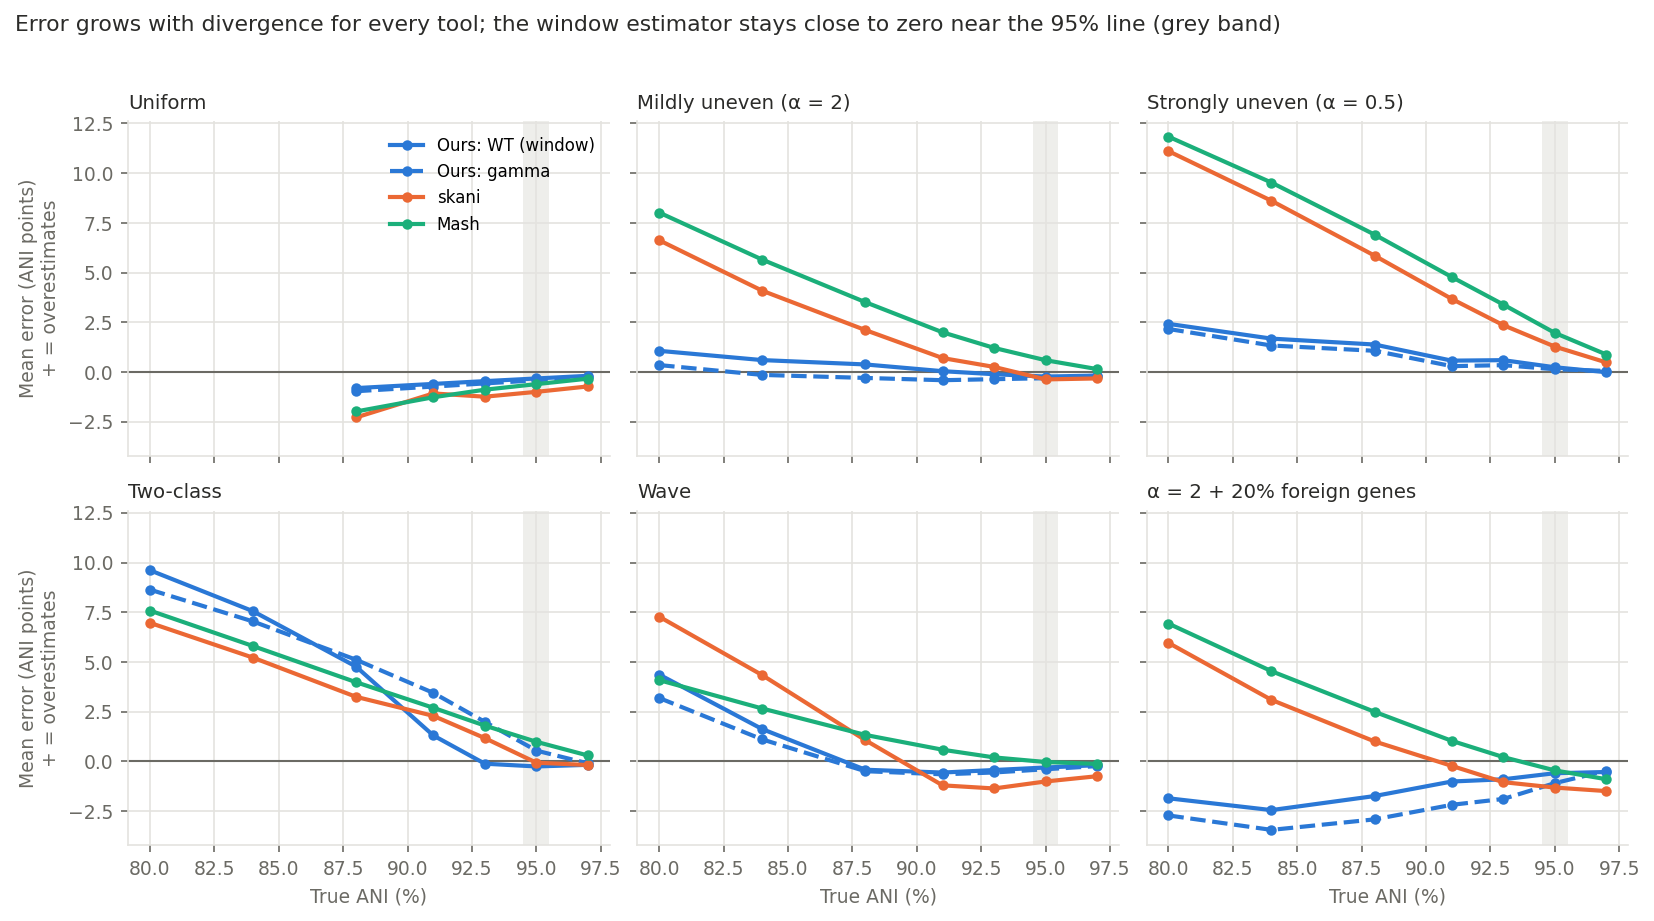

In [12]:
# ---------------- Figure 3: error vs divergence, Experiment 6 test replicates ----------------
import matplotlib.pyplot as plt
INK, INK2, GRID = "#2b2b29", "#6b6a64", "#e4e3df"
LINES = [("WT: windows + gamma tail", "Ours: WT (window)", "#2a78d6", "-"), ("original", "Ours: gamma", "#2a78d6", "--"),
         ("skani", "skani", "#eb6834", "-"), ("Mash (tool)", "Mash", "#1baf7a", "-")]
TITLES = {"Uniform": "Uniform", "Gamma a=2": "Mildly uneven (α = 2)", "Gamma a=0.5": "Strongly uneven (α = 0.5)",
          "Two-class": "Two-class", "Wave": "Wave", "Gamma a=2 + 20% foreign genes": "α = 2 + 20% foreign genes"}
plt.rcParams.update({"font.size": 9, "axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK2})
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2), dpi=150, sharex=True, sharey=True)
for ax, s in zip(axes.flat, ORDER):
    d = test[test.setting == s]
    ax.axhline(0, color=INK2, lw=1); ax.axvspan(94.5, 95.5, color=GRID, alpha=0.6, lw=0)
    for col, lab, colr, ls in LINES:
        g = d.dropna(subset=[col]).groupby("target")[f"err::{col}"].mean()
        ax.plot(g.index * 100, g.values, ls, color=colr, lw=2, marker="o", ms=4, label=lab)
    ax.set_title(TITLES[s], loc="left", fontsize=9.5, color=INK); ax.grid(color=GRID); ax.spines[["top", "right"]].set_visible(False)
for ax in axes[1, :]: ax.set_xlabel("True ANI (%)", color=INK2)
for ax in axes[:, 0]: ax.set_ylabel("Mean error (ANI points)\n+ = overestimates", color=INK2)
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Error grows with divergence for every tool; the window estimator stays close to zero near the 95% line (grey band)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.96)); plt.savefig(f"{OUTF}/fig3_exp6_error_vs_divergence.png", bbox_inches="tight", facecolor="white")
print("Saved:", f"{OUTF}/fig3_exp6_error_vs_divergence.png"); plt.show()

## Part D: real genomes

=== Real genomes: each method minus dnadiff ===
      pairs                   method  n  minus dnadiff         95% CI
development                  dnadiff 73           0.00 [+0.00, +0.00]
development              nucmer -l15 73          -0.27 [-0.34, -0.20]
development                  FastANI 73          -0.53 [-0.67, -0.40]
development                     ANIb 73          -0.87 [-1.08, -0.66]
development              Mash (tool) 73           0.30 [+0.22, +0.38]
development                    skani 73          -0.50 [-0.64, -0.36]
development                 original 73          -2.11 [-2.66, -1.57]
development              C: window s 73          -0.66 [-0.86, -0.46]
development         W2: windows only 73           0.30 [+0.21, +0.41]
development WT: windows + gamma tail 73          -1.06 [-1.56, -0.57]
   held-out                  dnadiff 27           0.00 [+0.00, +0.00]
   held-out              nucmer -l15 27          -0.35 [-0.49, -0.23]
   held-out                  FastANI 27   

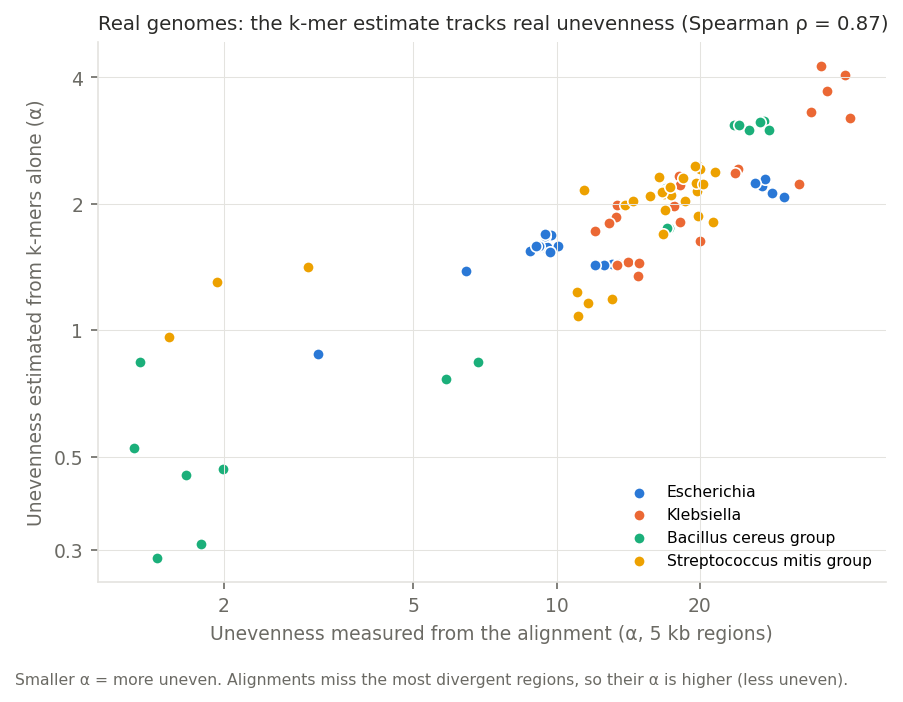

In [13]:
# ---------------- Part D: real genomes: window estimator next to the aligners, and alpha validation figure ----------------
from final_lib.window_est import est_window_tail_real
from final_lib.real_part import real_curve, boot_ci
rows = []
for p in R.itertuples():
    F = dict(np.load(f"{RESULTS}/{'multitool' if p.set == 'held-out' else 'Part2'}/features/{p.acc_a}__{p.acc_b}.npz"))
    C, sw = real_curve(F); _, _, d, a, _ = gamma_fit(C)
    WT, W2, pinv = est_window_tail_real(F, d, a)
    rows.append({"W2: windows only": W2, "WT: windows + gamma tail": WT})
RR = pd.concat([R, pd.DataFrame(rows)], axis=1).dropna(subset=["ANIb", "FastANI", "nucmer -l15"])
METH = ["dnadiff", "nucmer -l15", "FastANI", "ANIb", "Mash (tool)", "skani", "original", "C: window s",
        "W2: windows only", "WT: windows + gamma tail"]
rows = []
for S in ["development", "held-out"]:
    d = RR[RR.set == S]
    for m in METH:
        x = (d[m] - d.dnadiff).values * 100; lo, hi = boot_ci(x)
        rows.append({"pairs": S, "method": m, "n": len(d), "minus dnadiff": round(x.mean(), 2), "95% CI": f"[{lo:+.2f}, {hi:+.2f}]"})
RANK2 = pd.DataFrame(rows); RANK2.to_csv(f"{OUTF}/real_ranking_with_window.csv", index=False)
print("=== Real genomes: each method minus dnadiff ==="); print(RANK2.to_string(index=False))
by = (RR.assign(bin=pd.cut(RR.dnadiff, [.8, .9, .95, .99])).groupby("bin", observed=True)[METH].mean() * 100).round(2).T
print("\nMean ANI (%) by divergence:"); print(by.to_string())

fig, ax = plt.subplots(figsize=(6, 4.6), dpi=150)
GEN_C = {"Escherichia": "#2a78d6", "Klebsiella": "#eb6834", "Bacillus cereus group": "#1baf7a", "Streptococcus mitis group": "#eda100"}
for g, colr in GEN_C.items():
    d = HET[(HET.genus == g) & (HET.alpha_kmer < 999)]
    ax.scatter(d.alpha_alignment, d.alpha_kmer, s=30, color=colr, edgecolor="white", lw=0.8, label=g)
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(color=GRID, lw=0.5)
from matplotlib.ticker import FixedLocator, NullLocator, FuncFormatter
for axis, t in [(ax.xaxis, [1, 2, 5, 10, 20, 50]), (ax.yaxis, [0.3, 0.5, 1, 2, 4])]:
    axis.set_major_locator(FixedLocator(t)); axis.set_minor_locator(NullLocator()); axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("Unevenness measured from the alignment (α, 5 kb regions)", color=INK2)
ax.set_ylabel("Unevenness estimated from k-mers alone (α)", color=INK2)
ax.set_title(f"Real genomes: the k-mer estimate tracks real unevenness (Spearman ρ = {rho.statistic:.2f})", loc="left", fontsize=9.5, color=INK)
ax.spines[["top", "right"]].set_visible(False); ax.legend(frameon=False, fontsize=7.5, loc="lower right")
fig.text(0.01, 0.0, "Smaller α = more uneven. Alignments miss the most divergent regions, so their α is higher (less uneven).",
         fontsize=7.5, color=INK2)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.savefig(f"{OUTF}/fig4_real_alpha_validation.png", bbox_inches="tight", facecolor="white")
print("Saved:", f"{OUTF}/fig4_real_alpha_validation.png"); plt.show()

## Part E: Experiment 7 results and sketches

In [14]:
# ---------------- wait for Experiment 7 (prints progress every minute; safe to re-run) ----------------
def n_done7():
    fs = [f for f in glob.glob(f"{OUT7}/raw_w*.csv") if ("_quick" in f) == QUICK7]
    return len(pd.concat([pd.read_csv(f) for f in fs]).job.unique()) if fs else 0
t0, start = time.time(), n_done7()
while any(p.poll() is None for p in running7.values()):
    time.sleep(60); d = n_done7(); rate = (d - start) / max(time.time() - t0, 1)
    print(f"{time.strftime('%H:%M')}  {d}/{TOTAL7} pairs  |  ~{(TOTAL7 - d) / rate / 60 if rate > 0 else float('nan'):.0f} min left", flush=True)
for w, p in running7.items():
    print(f"worker {w}: exit {p.returncode} |", open(f"{OUT7}/log_w{w}{TAG7}.txt").read().strip().splitlines()[-1])
print("Experiment 7 pairs finished:", n_done7(), "/", TOTAL7)

00:01  19/360 pairs  |  ~114 min left
00:02  22/360 pairs  |  ~113 min left
00:03  24/360 pairs  |  ~126 min left
00:04  27/360 pairs  |  ~121 min left
00:05  30/360 pairs  |  ~118 min left
00:06  32/360 pairs  |  ~123 min left
00:07  34/360 pairs  |  ~127 min left
00:08  37/360 pairs  |  ~123 min left
00:09  39/360 pairs  |  ~126 min left
00:10  42/360 pairs  |  ~122 min left
00:11  45/360 pairs  |  ~120 min left
00:12  47/360 pairs  |  ~121 min left
00:13  50/360 pairs  |  ~119 min left
00:14  53/360 pairs  |  ~116 min left
00:15  55/360 pairs  |  ~117 min left
00:16  57/360 pairs  |  ~118 min left
00:17  61/360 pairs  |  ~113 min left
00:18  63/360 pairs  |  ~114 min left
00:19  65/360 pairs  |  ~114 min left
00:20  69/360 pairs  |  ~110 min left
00:21  71/360 pairs  |  ~110 min left
00:22  73/360 pairs  |  ~111 min left
00:23  76/360 pairs  |  ~109 min left
00:24  79/360 pairs  |  ~107 min left
00:25  81/360 pairs  |  ~107 min left
00:26  83/360 pairs  |  ~108 min left
00:27  87/36

In [15]:
# ---------------- Part E: Experiment 7 results (real rate profiles) + sketched (fast) version ----------------
from final_lib.estimators import est_two_class
def est7(j):
    F = dict(np.load(f"{OUT7}/curves{TAG7}/job_{j}.npz")); ks = F["ks"]; m = np.isin(ks, KS)
    C = np.maximum(F["shared"][m] - F["nA"][m] * F["nB"][m] / 4.0 ** ks[m], 1) / F["nA"][m]
    sw = min((F["win21"] >= 1).mean(), 1)
    ani, _, d, a, _ = gamma_fit(C); aniC = gamma_fit(C, sw)[0]
    WT, W2, _ = est_window_tail(F, d, a)
    out = {"job": j, "original (check)": ani, "C: window s": aniC, "two-class": est_two_class(C)[0],
           "W2: windows only": W2, "WT: windows + gamma tail": WT}
    for sc in (100, 1000):                                        # same estimator on FracMinHash sketches
        nA, nB, sh = (F[f"s{sc}_{x}"].astype(float) for x in ("nA", "nB", "shared"))
        Cs = np.maximum(sh - nA * nB * sc / 4.0 ** KS, 1) / np.maximum(nA, 1)
        out[f"ours, sketch 1/{sc}"] = gamma_fit(Cs)[0]
        out[f"sketch 1/{sc}: k-mers kept (A, k=21)"] = int(nA[list(KS).index(21)])
    return out
raw7 = pd.concat([pd.read_csv(f) for f in glob.glob(f"{OUT7}/raw_w*.csv") if ("_quick" in f) == QUICK7]).drop_duplicates("job")
with get_context("fork").Pool(os.cpu_count()) as pool: e7 = pd.DataFrame(pool.map(est7, raw7.job.tolist(), chunksize=4))
X7 = raw7.merge(e7, on="job").merge(PROF[["profile_id", "genus", "alpha_alignment"]], on="profile_id")
assert np.allclose(X7["original (check)"], X7["original"], atol=1e-9)
X7.to_csv(f"{OUTF}/exp7_all_estimates{TAG7}.csv", index=False)
E7 = ["Mash (tool)", "sourmash", "skani", "original", "C: window s", "two-class", "W2: windows only", "WT: windows + gamma tail",
      "ours, sketch 1/100", "ours, sketch 1/1000"]
c7 = X7.dropna(subset=["skani", "sourmash"]).copy()
for e in E7: c7[f"err::{e}"] = (c7[e] - c7.true) * 100
print(f"Experiment 7: {len(c7)} of {len(X7)} pairs scored (24 real profiles x 3 chromosomes x 5 ANI levels)")
T7 = pd.DataFrame({e: {**{f"ANI {int(t * 100)}%": c7[c7.target == t][f"err::{e}"].abs().mean() for t in sorted(c7.target.unique())},
                        "ALL": c7[f"err::{e}"].abs().mean(), "mean error (+ = over)": c7[f"err::{e}"].mean(),
                        "wrong side of 95%": int((((c7.true < .95) & (c7[e] >= .95)) | ((c7.true >= .95) & (c7[e] < .95)))[(c7.true - .95).abs() > .005].sum())}
                    for e in E7}).T
print("\n=== Experiment 7: mean |error| vs true ANI, by ANI level ==="); print(T7.round(2).to_string())
T7.round(3).to_csv(f"{OUTF}/exp7_summary{TAG7}.csv")
strong = c7[c7.alpha_alignment < 5]
print(f"\nProfiles with strong real unevenness (alignment alpha < 5, {strong.profile_id.nunique()} profiles): mean |error|")
print(pd.Series({e: strong[f"err::{e}"].abs().mean() for e in E7}).round(2).to_string())
print("\nSketch sizes (k-mers kept from genome A at k = 21): 1/100 ->", int(X7["sketch 1/100: k-mers kept (A, k=21)"].median()),
      "| 1/1000 ->", int(X7["sketch 1/1000: k-mers kept (A, k=21)"].median()))

Experiment 7: 360 of 360 pairs scored (24 real profiles x 3 chromosomes x 5 ANI levels)

=== Experiment 7: mean |error| vs true ANI, by ANI level ===
                          ANI 85%  ANI 88%  ANI 91%  ANI 94%  ANI 97%   ALL  mean error (+ = over)  wrong side of 95%
Mash (tool)                  1.24     0.97     0.74     0.49     0.24  0.74                  -0.05                5.0
sourmash                     1.42     0.88     0.54     0.36     0.18  0.67                   0.46                5.0
skani                        1.31     1.34     0.88     0.81     0.67  1.00                  -0.67                0.0
original                     1.16     0.81     0.58     0.38     0.20  0.63                  -0.40                0.0
C: window s                  1.05     0.89     0.63     0.37     0.21  0.63                  -0.19                0.0
two-class                    0.60     0.48     0.41     0.30     0.19  0.40                  -0.06                0.0
W2: windows only        

Saved: /content/drive/MyDrive/CMPS355_ANI_Project/results/final/fig5_exp7_real_profiles.png


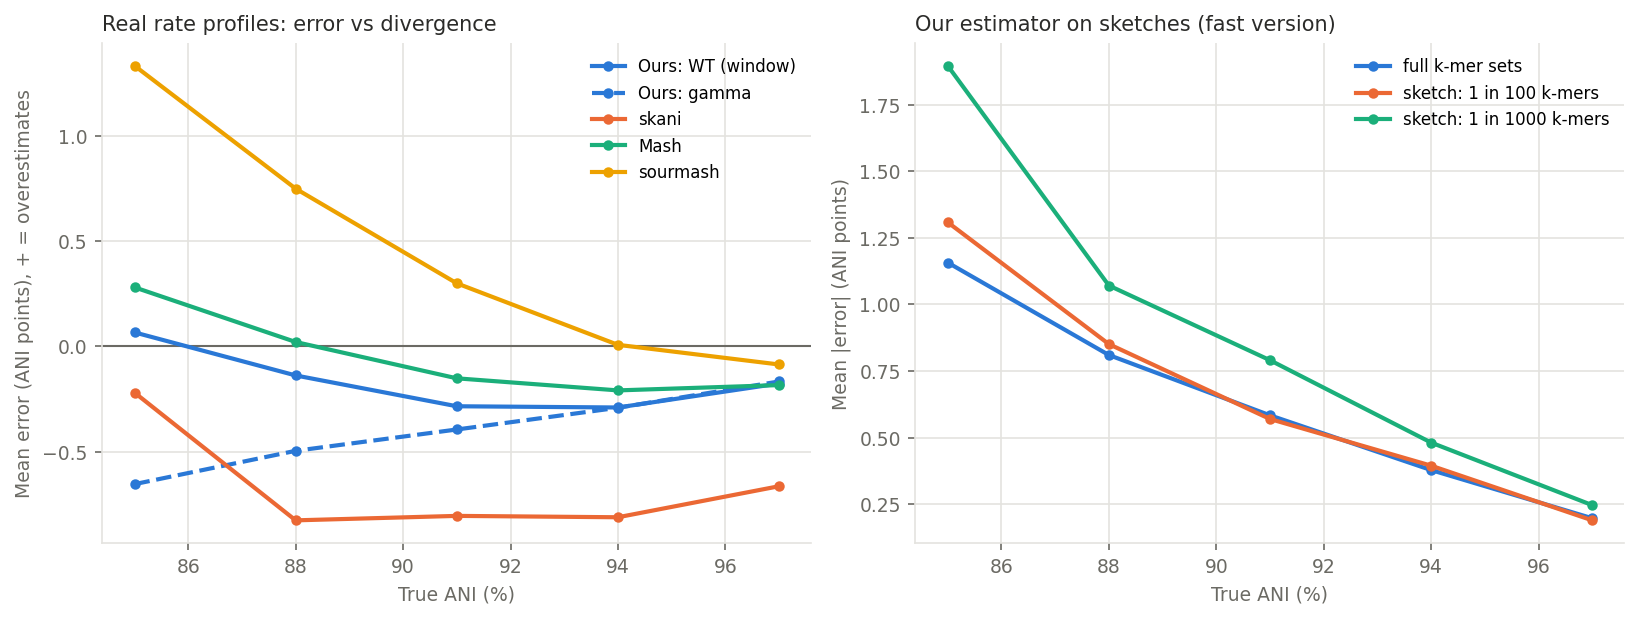

In [16]:
# ---------------- Figure 5: Experiment 7 (real rate profiles) ----------------
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), dpi=150)
L7 = [("WT: windows + gamma tail", "Ours: WT (window)", "#2a78d6", "-"), ("original", "Ours: gamma", "#2a78d6", "--"),
      ("skani", "skani", "#eb6834", "-"), ("Mash (tool)", "Mash", "#1baf7a", "-"), ("sourmash", "sourmash", "#eda100", "-")]
ax = axes[0]; ax.axhline(0, color=INK2, lw=1)
for col, lab, colr, ls in L7:
    g = c7.groupby("target")[f"err::{col}"].mean(); ax.plot(g.index * 100, g.values, ls, color=colr, lw=2, marker="o", ms=4, label=lab)
ax.set_xlabel("True ANI (%)", color=INK2); ax.set_ylabel("Mean error (ANI points), + = overestimates", color=INK2)
ax.set_title("Real rate profiles: error vs divergence", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8); ax.grid(color=GRID); ax.spines[["top", "right"]].set_visible(False)
ax = axes[1]
S7 = [("original", "full k-mer sets"), ("ours, sketch 1/100", "sketch: 1 in 100 k-mers"), ("ours, sketch 1/1000", "sketch: 1 in 1000 k-mers")]
for i, (col, lab) in enumerate(S7):
    g = c7.groupby("target")[f"err::{col}"].apply(lambda x: x.abs().mean())
    ax.plot(g.index * 100, g.values, "-", color=["#2a78d6", "#eb6834", "#1baf7a"][i], lw=2, marker="o", ms=4, label=lab)
ax.set_xlabel("True ANI (%)", color=INK2); ax.set_ylabel("Mean |error| (ANI points)", color=INK2)
ax.set_title("Our estimator on sketches (fast version)", loc="left", fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8); ax.grid(color=GRID); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUTF}/fig5_exp7_real_profiles{TAG7}.png", bbox_inches="tight", facecolor="white")
print("Saved:", f"{OUTF}/fig5_exp7_real_profiles{TAG7}.png"); plt.show()

## Part F: key numbers

In [17]:
# ---------------- Part F: new key numbers ----------------
g = lambda t, r, c: float(t.loc[r, c]) if (r in t.index and c in t.columns) else float("nan")
W, O = "WT: windows + gamma tail", "original"
pw = P6.set_index(["WT vs", "pairs"])
L = ["NEW KEY NUMBERS",
 f"Window estimator WT (Exp 6 TEST replicates 1-9): mean |error| uneven {g(T6, W, 'ALL uneven'):.2f} vs ours-gamma {g(T6, O, 'ALL uneven'):.2f}, "
 f"skani {g(T6, 'skani', 'ALL uneven'):.2f}, Mash {g(T6, 'Mash (tool)', 'ALL uneven'):.2f}",
 f"   near the 95% line: WT {g(T6, W, 'near 95% (90-97.5)'):.2f} vs ours-gamma {g(T6, O, 'near 95% (90-97.5)'):.2f}, skani {g(T6, 'skani', 'near 95% (90-97.5)'):.2f}, "
 f"Mash {g(T6, 'Mash (tool)', 'near 95% (90-97.5)'):.2f}",
 f"   two-class: WT {g(T6, W, 'Two-class'):.2f} vs ours-gamma {g(T6, O, 'Two-class'):.2f}; foreign genes: WT {g(T6, W, 'Gamma a=2 + 20% foreign genes'):.2f} vs {g(T6, O, 'Gamma a=2 + 20% foreign genes'):.2f}",
 f"   wrong side of 95%: WT {int(g(T6, W, 'wrong side of 95%'))}, ours-gamma {int(g(T6, O, 'wrong side of 95%'))}, skani {int(g(T6, 'skani', 'wrong side of 95%'))}, "
 f"Mash {int(g(T6, 'Mash (tool)', 'wrong side of 95%'))} (of {int(g(T6, W, 'pairs counted (95%)'))})",
 f"   WT minus ours-gamma near 95%: {pw.loc[(O, 'near 95%'), 'difference']} {pw.loc[(O, 'near 95%'), '95% CI']}",
 "",
 f"Real genomes: k-mer alpha vs alignment alpha Spearman {rho.statistic:.2f} (n={ok.sum()}); neighbouring-region correlation {HET.lag1_autocorr.median():.2f};",
 f"   real rate distribution is gamma-like (alpha {a_pool:.1f} among aligned regions); near-zero-rate regions {(rel < .25).mean():.1%}",
 "",
 f"Experiment 7 (real rate profiles, {len(c7)} pairs): mean |error| WT {g(T7, W, 'ALL'):.2f}, ours-gamma {g(T7, O, 'ALL'):.2f}, skani {g(T7, 'skani', 'ALL'):.2f}, "
 f"Mash {g(T7, 'Mash (tool)', 'ALL'):.2f}, sourmash {g(T7, 'sourmash', 'ALL'):.2f}",
 f"   mean error (bias): Mash {g(T7, 'Mash (tool)', 'mean error (+ = over)'):+.2f}, skani {g(T7, 'skani', 'mean error (+ = over)'):+.2f}, ours-gamma {g(T7, O, 'mean error (+ = over)'):+.2f}, WT {g(T7, W, 'mean error (+ = over)'):+.2f}",
 f"   sketched version: 1/100 {g(T7, 'ours, sketch 1/100', 'ALL'):.2f}, 1/1000 {g(T7, 'ours, sketch 1/1000', 'ALL'):.2f} (full {g(T7, O, 'ALL'):.2f})",
]
txt = "\n".join(L); open(f"{OUTF}/key_numbers_v2.txt", "w").write(txt); print(txt)

NEW KEY NUMBERS
Window estimator WT (Exp 6 TEST replicates 1-9): mean |error| uneven 1.47 vs ours-gamma 1.64, skani 2.81, Mash 3.12
   near the 95% line: WT 0.43 vs ours-gamma 0.77, skani 1.07, Mash 1.14
   two-class: WT 3.40 vs ours-gamma 3.84; foreign genes: WT 1.37 vs 2.15
   wrong side of 95%: WT 0, ours-gamma 18, skani 35, Mash 88 (of 921)
   WT minus ours-gamma near 95%: -0.34 [-0.39, -0.29]

Real genomes: k-mer alpha vs alignment alpha Spearman 0.87 (n=93); neighbouring-region correlation 0.57;
   real rate distribution is gamma-like (alpha 5.8 among aligned regions); near-zero-rate regions 0.8%

Experiment 7 (real rate profiles, 360 pairs): mean |error| WT 0.54, ours-gamma 0.63, skani 1.00, Mash 0.74, sourmash 0.67
   mean error (bias): Mash -0.05, skani -0.67, ours-gamma -0.40, WT -0.16
   sketched version: 1/100 0.66, 1/1000 0.90 (full 0.63)
